# Application A: reduced proper motion diagram (pilot)

Reduced proper motion $H_r = r + 5\log_{10}\mu + 5$ ($\mu$ in arcsec/yr) is a proxy for absolute magnitude
($H = M + 5\log_{10}(v_{\rm tan}/4.74\,{\rm km\,s^{-1}})$), so the $H_r$ vs $g-z$ diagram separates main-sequence
stars, subdwarfs and white dwarfs without parallaxes. The point: our PMs reach r ~ 24, three magnitudes past Gaia,
so the white-dwarf / halo region of the diagram fills in with objects Gaia cannot measure.

* Data: v2 catalogues (`legacypm-catalogue-v2/`, read-only), N_BRICKS random bricks with centres in RA 25-35, Dec -40 to -30 (field A; field B = RA 5-15, Dec -20 to -10, held out)
  ($b \approx -70^\circ$ to $-80^\circ$).
* Selection: `brick_primary`, `type == 'PSF'`, `pm_quality == 0`, $\mu > $ MU_MIN, $\mu/\sigma_\mu > 4$, g, r, z measured,
  $S/N_r >$ SNR_R_MIN (= 30; see the false-positive and PM-direction checks below: at lower S/N the 'HPM' objects are mostly
  noise). The first version used $r_0 < 23$, which matches S/N_r > 30 in field A but not in the shallower field B.
  $\sigma_\mu = \sqrt{1/\mathrm{ivar}_{\alpha} + 1/\mathrm{ivar}_{\delta}}$ (per-axis errors combined; conservative).
  Magnitudes are extinction corrected (`mw_transmission`). PMs are `pmra_no_plx`, `pmdec_no_plx` (absolute, Gaia stars included).
* WD tracks: Montreal 0.6 Msun pure-H (DA) cooling sequence (Bergeron et al. 1995; Bedard et al. 2020; SDSS-system g, r, z),
  `data/bergeron_Table_Mass_0.6.txt`, shifted to $v_{\rm tan}$ = 20 and 40 km/s (disc) and 200 km/s (halo).
* Pilot code lives in `application/`, separate from the pipeline and from `run/`. Plots go to `application/plots/`.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
import fitsio

REPO = os.path.abspath('..')
sys.path.insert(0, REPO); sys.path.insert(0, os.path.abspath('.'))
from py_files import plot_style as ps
import rpm
ps.apply()

N_BRICKS = 200         # 20 for the first pilot; 200 bricks = 12.5 deg^2, ~1-2 min to load
MU_MIN = 20.           # mas/yr; 15 for a fuller demonstration
SNR_MIN = 4.
SNR_R_MIN = 30.       # r-band S/N limit: below it the HPM sample is mostly noise (false-positive + PM-direction checks)
SEED = 1
# Field: A = the pilot field, where the faint limit and the WD cut were first chosen; B = a held-out field at the same Galactic latitude
# (b ~ -76 vs -78 deg) to check the numbers are not specific to field A. Run B with RPM_FIELD=B (outputs get _fieldB).
FIELDS = {'A': ((25, 35), (-40, -30)), 'B': ((5, 15), (-20, -10))}
FIELD = os.environ.get('RPM_FIELD', 'A')
RA_RANGE, DEC_RANGE = FIELDS[FIELD]
TAG = '' if FIELD == 'A' else f'_field{FIELD}'
PLOTS = 'plots'; OUT = 'output'

In [2]:
all_bricks = rpm.find_bricks(ra_range=RA_RANGE, dec_range=DEC_RANGE)
bricks = rpm.pick_bricks(all_bricks, N_BRICKS, seed=SEED)
print(f'field {FIELD}: RA {RA_RANGE}, Dec {DEC_RANGE}; {len(all_bricks)} bricks in the box; using {len(bricks)}:')
print(' '.join(os.path.basename(b)[11:-5] for b in bricks))
T = rpm.load(bricks)
d = rpm.derive(T)
sel = rpm.hpm_mask(T, d, mu_min=MU_MIN, snr_min=SNR_MIN, snr_r_min=SNR_R_MIN)
gaia = d['gaia']
psf_clean = T['brick_primary'] & (np.char.strip(T['type'].astype(str)) == 'PSF') & (T['pm_quality'] == 0)
print(f'{len(T):,} sources, {psf_clean.sum():,} clean primary PSF')
for mu in (15, 20):
    m = rpm.hpm_mask(T, d, mu_min=mu, snr_min=SNR_MIN, snr_r_min=SNR_R_MIN)
    print(f'mu > {mu}: {m.sum()} HPM objects; Gaia {np.sum(m & gaia)}, not Gaia {np.sum(m & ~gaia)} '
          f'(of which r > 21: {np.sum(m & ~gaia & (d["r"] > 21))})')

field A: RA (25, 35), Dec (-40, -30); 1310 bricks in the box; using 200:
0250m367 0250m377 0251m390 0252m345 0252m352 0252m355 0252m392 0253m305 0253m357 0254m310 0255m322 0255m355 0255m382 0256m315 0256m337 0257m320 0257m342 0257m370 0258m325 0260m360 0260m367 0260m377 0260m395 0261m362 0262m327 0263m387 0264m335 0264m345 0266m330 0267m362 0267m372 0269m367 0270m345 0270m355 0270m362 0271m327 0272m320 0273m305 0273m345 0273m372 0273m380 0273m387 0274m375 0274m382 0275m377 0275m400 0276m305 0276m325 0276m335 0276m370 0276m380 0278m360 0278m377 0279m305 0280m382 0281m322 0281m357 0282m360 0282m395 0283m327 0283m337 0283m347 0285m315 0285m317 0286m327 0286m337 0287m305 0287m382 0288m315 0288m317 0288m367 0289m320 0289m337 0289m347 0289m370 0290m322 0290m365 0291m307 0291m360 0291m367 0291m392 0292m387 0293m350 0293m382 0293m397 0294m315 0294m332 0294m360 0294m367 0294m400 0295m320 0296m312 0296m357 0296m375 0296m397 0297m317 0297m325 0297m377 0297m400 0300m307 0300m350 0301m370 0303m350 

2,031,131 sources, 589,775 clean primary PSF


mu > 15: 11653 HPM objects; Gaia 8739, not Gaia 2914 (of which r > 21: 2901)


mu > 20: 7449 HPM objects; Gaia 5540, not Gaia 1909 (of which r > 21: 1903)


## False-positive check: is a 4-sigma PM significant at faint magnitudes?

Faint non-Gaia PSF objects are mostly galaxies and QSOs (true PM = 0), so their PM pulls test the errors directly.
Gaussian errors give $P(\chi^2_2 > 16) = e^{-8} = 0.03\%$. (At r < 23 real stellar motions also raise the rates,
so this is only a clean test at the faint end.) Second table: the same in bins of r-band S/N, only r > 23 (few real movers).

In [3]:
base = (psf_clean & (T['pmra_no_plx_ivar'] > 0) & (T['pmdec_no_plx_ivar'] > 0) & ~gaia
        & np.isfinite(d['g']) & np.isfinite(d['r']) & np.isfinite(d['z']))
chi2 = T['pmra_no_plx']**2 * T['pmra_no_plx_ivar'] + T['pmdec_no_plx']**2 * T['pmdec_no_plx_ivar']
snr_r = T['flux_r'] * np.sqrt(T['flux_ivar_r'])
print('r_0         N    chi2>16  pull width (RA, MAD)  median sigma_mu  median S/N_r')
for lo, hi in [(21, 22), (22, 23), (23, 23.5), (23.5, 24), (24, 25), (25, 30)]:
    m = base & (d['r'] >= lo) & (d['r'] < hi)
    p = T['pmra_no_plx'][m] * np.sqrt(T['pmra_no_plx_ivar'][m])
    print(f'{lo:4.1f}-{hi:4.1f} {m.sum():7d}  {100*np.mean(chi2[m] > 16):5.1f}%  {1.4826*np.median(np.abs(p - np.median(p))):5.2f}'
          f'                 {np.median(d["mu_err"][m]):5.1f}            {np.median(snr_r[m]):5.1f}')
print('S/N_r (r > 23)     N    chi2>16  pull width (RA, MAD)')
for lo, hi in [(30, 60), (20, 30), (15, 20), (10, 15), (7, 10), (5, 7), (3, 5)]:
    m = base & (d['r'] > 23) & (snr_r >= lo) & (snr_r < hi)
    p = T['pmra_no_plx'][m] * np.sqrt(T['pmra_no_plx_ivar'][m])
    w = 1.4826 * np.median(np.abs(p - np.median(p))) if m.sum() > 50 else np.nan
    print(f'{lo:4.0f}-{hi:<4.0f}     {m.sum():7d}  {100*np.mean(chi2[m] > 16) if m.any() else np.nan:5.1f}%  {w:5.2f}')
n_all = rpm.hpm_mask(T, d, mu_min=MU_MIN, snr_min=SNR_MIN, snr_r_min=0).sum()
print(f'HPM objects without the S/N_r > {SNR_R_MIN:g} limit: {n_all}; with it: {sel.sum()}')

r_0         N    chi2>16  pull width (RA, MAD)  median sigma_mu  median S/N_r
21.0-22.0    8504   35.7%   2.21                   3.6             99.0
22.0-23.0   16879   18.4%   1.61                   7.5             44.9
23.0-23.5   15396    6.1%   1.24                  15.1             23.6
23.5-24.0   35523    5.3%   1.28                  23.9             14.9
24.0-25.0  271976   14.7%   1.74                  42.8              6.9
25.0-30.0  198853   25.4%   2.22                  50.9              4.1
S/N_r (r > 23)     N    chi2>16  pull width (RA, MAD)
  30-60          1940    9.0%   1.28


  20-30         12751    5.5%   1.25
  15-20         18308    4.9%   1.25
  10-15         53023    7.0%   1.39
   7-10         95230   12.4%   1.64
   5-7         158315   19.7%   1.96
   3-5         140135   24.0%   2.15


HPM objects without the S/N_r > 30 limit: 43402; with it: 7449


## Reality check: PM directions

Real stars share the solar reflex motion, so their PM directions cluster (at this position mostly towards
position angles opposite the solar apex). Noise has random directions. Comparing the direction distributions tells
which parts of the HPM sample are real, independently of the error model. Groups: Gaia stars; the selected non-Gaia
objects (S/N_r > 30); and the non-Gaia objects at S/N_r 15-30 that a looser limit would add. Last line: the fraction of
each group within 90 deg of the Gaia stars' mean direction, and the implied real fraction relative to the Gaia stars.

Gaia (GE)                    N= 5540  max/min bin 196.6  frac mu/sigma 4-5 0.00  median mu   28.8  median g-z 2.98  near Gaia direction 0.92 -> real ~1.00
not in Gaia, S/N$_r > 30$    N= 1909  max/min bin 497.0  frac mu/sigma 4-5 0.17  median mu   27.2  median g-z 2.98  near Gaia direction 0.95 -> real ~1.07
not in Gaia, S/N$_r$ 15-30   N=  643  max/min bin  10.8  frac mu/sigma 4-5 0.40  median mu   62.0  median g-z 2.87  near Gaia direction 0.69 -> real ~0.45


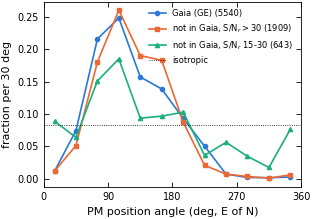

In [4]:
loose = rpm.hpm_mask(T, d, mu_min=MU_MIN, snr_min=SNR_MIN, snr_r_min=15)
pa = np.degrees(np.arctan2(T['pmra_no_plx'], T['pmdec_no_plx'])) % 360   # position angle, east of north
groups = [('Gaia (GE)', sel & gaia), (rf'not in Gaia, S/N$_r > {SNR_R_MIN:g}$', sel & ~gaia),
          (rf'not in Gaia, S/N$_r$ 15-{SNR_R_MIN:g}', loose & ~gaia & (d['snr_r'] <= SNR_R_MIN))]
ref = np.angle(np.mean(np.exp(1j * np.radians(pa[sel & gaia]))))   # mean direction of the Gaia HPM stars
near = np.cos(np.radians(pa) - ref) > 0
pg = near[sel & gaia].mean()
bins = np.arange(0, 361, 30); cen = 0.5 * (bins[1:] + bins[:-1])
fig, ax = plt.subplots(figsize=(ps.COLUMN, 2.4))
for i, (lab, m) in enumerate(groups):
    h = np.histogram(pa[m], bins)[0]
    ax.plot(cen, h / h.sum(), color=ps.SERIES[i], marker=ps.MARKERS[i], ms=3, label=f'{lab} ({m.sum()})')
    snr = d['mu'][m] / d['mu_err'][m]
    print(f'{lab:28s} N={m.sum():5d}  max/min bin {h.max()/max(h.min(), 1):5.1f}  '
          f'frac mu/sigma 4-5 {np.mean(snr < 5):.2f}  median mu {np.median(d["mu"][m]):6.1f}  median g-z {np.median(d["g_z"][m]):.2f}  '
          f'near Gaia direction {near[m].mean():.2f} -> real ~{(near[m].mean() - 0.5) / (pg - 0.5):.2f}')
ax.axhline(1 / len(cen), color='k', lw=0.6, ls=':', label='isotropic')
ax.set_xlabel('PM position angle (deg, E of N)'); ax.set_ylabel('fraction per 30 deg'); ax.set_xlim(0, 360)
ax.set_xticks(range(0, 361, 90)); ax.legend(fontsize=6)
fig.savefig(f'{PLOTS}/rpm_pm_direction_mu{int(MU_MIN)}_n{len(bricks)}{TAG}.pdf')
fig.savefig(f'{PLOTS}/rpm_pm_direction_mu{int(MU_MIN)}_n{len(bricks)}{TAG}.png')

g-z = -1, 0, 1, 2, 3, 4 -> BP-RP = [0.04 0.48 1.07 1.72 2.33 2.82]
  g-z 0-1:  4599 Gaia stars, median offset +0.019
  g-z 1-2:  2900 Gaia stars, median offset +0.004
  g-z 2-3:  4182 Gaia stars, median offset -0.018
  g-z 3-4:  2873 Gaia stars, median offset +0.085


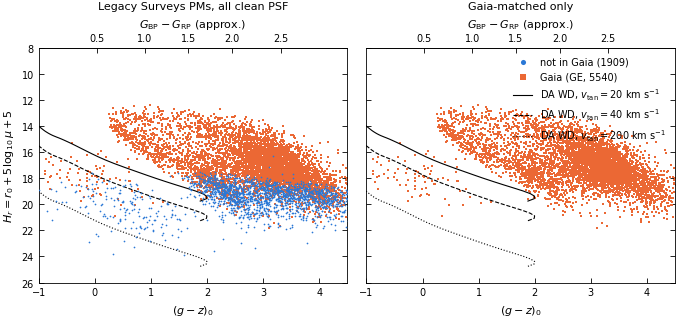

In [5]:
tracks = rpm.wd_tracks()
teff, gz_wd, Mr_wd = tracks['DA']
keep = (teff >= 3000) & (teff <= 30000)
# Second colour axis (top): Gaia BP - RP. g - z -> BP - RP via the pipeline's relations (colour_fallback cubic, then
# g - i = -0.56 + 1.34 (BP - RP)); g - r has no pipeline relation, so the median dereddened BP - RP of the clean Gaia
# stars in bins of g - r (bluer: the DA track). Saved for wd-vetting.ipynb.
rel_gz = rpm.gz_bprp_table()
bright = gaia & psf_clean & (T['gaia_phot_g_mean_mag'] < 20) \
    & (T['gaia_phot_bp_mean_mag'] > 0) & (T['gaia_phot_rp_mean_mag'] > 0)
bprp = np.where(bright, T['gaia_phot_bp_mean_mag'] - T['gaia_phot_rp_mean_mag'] - 1.339 * T['ebv'], np.nan)  # E(BP-RP) = 1.339 E(B-V)
rel_gr = rpm.bprp_relation(d['g'] - d['r'], bprp, 'g_r', x_max=1.2)   # g - r saturates for M dwarfs
np.savez(f'{OUT}/bprp_relation{TAG}.npz', g_z=np.array(rel_gz), g_r=np.array(rel_gr))
print('g-z = -1, 0, 1, 2, 3, 4 -> BP-RP =', np.round(np.interp([-1, 0, 1, 2, 3, 4], *rel_gz), 2))
# check against the Gaia stars in these bricks: median (measured - relation) BP - RP in g - z bins
for lo in (0, 1, 2, 3):
    m = np.isfinite(bprp) & (d['g_z'] >= lo) & (d['g_z'] < lo + 1)
    print(f'  g-z {lo}-{lo + 1}: {m.sum():5d} Gaia stars, median offset {np.median(bprp[m] - np.interp(d["g_z"][m], *rel_gz)):+.3f}')

VTANS = [(20, '-'), (40, '--'), (200, ':')]   # disc WDs at 20-40 km/s; halo WDs at ~200 km/s

def rpm_panel(ax, m, title):
    ax.scatter(d['g_z'][m & ~gaia], d['H_r'][m & ~gaia], s=1.5, marker=ps.MARKERS[0], color=ps.SERIES[0], zorder=3,
               lw=0, label=f'not in Gaia ({np.sum(m & ~gaia)})')
    ax.scatter(d['g_z'][m & gaia], d['H_r'][m & gaia], s=1.5, marker=ps.MARKERS[1], color=ps.SERIES[1], zorder=2,
               lw=0, label=f'Gaia (GE, {np.sum(m & gaia)})')
    for v, ls in VTANS:
        ax.plot(gz_wd[keep], rpm.H_from_M(Mr_wd[keep], v), color='k', ls=ls, lw=0.8,
                label=rf'DA WD, $v_{{\rm tan}}={v}$ km s$^{{-1}}$')
    ax.set_title(title)
    ax.set_xlabel(r'$(g - z)_0$')
    rpm.add_bprp_axis(ax, rel_gz)

fig, axes = plt.subplots(1, 2, figsize=(ps.PAGE, 3.4), sharex=True, sharey=True)
rpm_panel(axes[0], sel, 'Legacy Surveys PMs, all clean PSF')
rpm_panel(axes[1], sel & gaia, 'Gaia-matched only')
axes[0].set_ylabel(r'$H_r = r_0 + 5\log_{10}\mu + 5$')
axes[0].set_xlim(-1, 4.5); axes[0].set_ylim(26, 8)
h, l = axes[0].get_legend_handles_labels()
axes[1].legend(h, l, loc='upper right', markerscale=3)
fig.tight_layout()
os.makedirs(PLOTS, exist_ok=True)
for ext in ('pdf', 'png'):
    fig.savefig(f'{PLOTS}/rpm_diagram_mu{int(MU_MIN)}_n{len(bricks)}{TAG}.{ext}')

Magnitude reach of the HPM sample: Gaia-matched vs not.

r 14-19: 2063 HPM, 2063 Gaia, median sigma_mu 1.3 mas/yr
r 19-21: 2753 HPM, 2747 Gaia, median sigma_mu 1.7 mas/yr
r 21-22: 1479 HPM,  703 Gaia, median sigma_mu 2.8 mas/yr
r 22-23: 1086 HPM,   27 Gaia, median sigma_mu 4.2 mas/yr


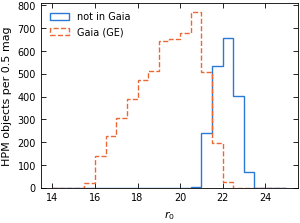

In [6]:
fig, ax = plt.subplots(figsize=(ps.COLUMN, 2.4))
bins = np.arange(14, 25.01, 0.5)
ax.hist(d['r'][sel & ~gaia], bins, histtype='step', color=ps.SERIES[0], label='not in Gaia')
ax.hist(d['r'][sel & gaia], bins, histtype='step', color=ps.SERIES[1], ls='--', label='Gaia (GE)')
ax.set_xlabel(r'$r_0$'); ax.set_ylabel('HPM objects per 0.5 mag'); ax.legend()
fig.savefig(f'{PLOTS}/rpm_rmag_hist_mu{int(MU_MIN)}_n{len(bricks)}{TAG}.pdf')
for lo, hi in [(14, 19), (19, 21), (21, 22), (22, 23)]:
    m = sel & (d['r'] >= lo) & (d['r'] < hi)
    print(f'r {lo}-{hi}: {m.sum():4d} HPM, {np.sum(m & gaia):4d} Gaia, median sigma_mu {np.median(d["mu_err"][m]) if m.any() else np.nan:.1f} mas/yr')

White-dwarf candidates (crude, for this pilot): bluer than $g - z = 1.5$ and no more than 1.5 mag brighter in
$H_r$ than the 40 km/s DA track, i.e. too faint for its colour to be a main-sequence star at disc velocities.
The HPM table goes to `output/` for TopCat / Legacy Viewer inspection.

In [7]:
H40 = rpm.wd_track_H(d['g_z'], 40, tracks=tracks)
wd_cand = sel & (d['g_z'] < 1.5) & (d['H_r'] > H40 - 1.5)
print(f'{wd_cand.sum()} WD candidates ({np.sum(wd_cand & gaia)} in Gaia, {np.sum(wd_cand & ~gaia)} not = '
      f'{np.sum(wd_cand & ~gaia) / (len(bricks) * 0.0625):.1f} per deg2)')
nw = near[wd_cand & gaia].mean()
for lab, m in [('all', wd_cand & ~gaia), ('mu/sigma > 6', wd_cand & ~gaia & (d['mu'] / d['mu_err'] > 6)),
               ('mu/sigma 4-6', wd_cand & ~gaia & (d['mu'] / d['mu_err'] <= 6))]:
    f = near[m].mean()
    print(f'  non-Gaia WD candidates, {lab:12s} N={m.sum():4d}: near Gaia direction {f:.2f} (Gaia WD candidates {nw:.2f}) '
          f'-> real ~{(f - 0.5) / (nw - 0.5):.2f} +- {np.sqrt(f * (1 - f) / m.sum()) / (nw - 0.5):.2f}')
os.makedirs(OUT, exist_ok=True)
out = {k: T[k][sel] for k in ('brickname', 'objid', 'ra', 'dec', 'ref_cat', 'pmra_no_plx', 'pmdec_no_plx',
                               'pmra_no_plx_ivar', 'pmdec_no_plx_ivar', 'pm_n_epochs', 'pm_baseline_days')}
for k in ('g', 'r', 'z', 'g_z', 'mu', 'mu_err', 'H_r', 'snr_r'):
    out[k] = d[k][sel]
out['wd_candidate'] = wd_cand[sel]
fn = f'{OUT}/hpm_mu{int(MU_MIN)}_n{len(bricks)}{TAG}.fits'
fitsio.write(fn, out, names=list(out), clobber=True)
print('wrote', fn)

235 WD candidates (74 in Gaia, 161 not = 12.9 per deg2)
  non-Gaia WD candidates, all          N= 161: near Gaia direction 0.81 (Gaia WD candidates 0.78) -> real ~1.11 +- 0.11
  non-Gaia WD candidates, mu/sigma > 6 N=  79: near Gaia direction 0.89 (Gaia WD candidates 0.78) -> real ~1.36 +- 0.13
  non-Gaia WD candidates, mu/sigma 4-6 N=  82: near Gaia direction 0.74 (Gaia WD candidates 0.78) -> real ~0.86 +- 0.17
wrote output/hpm_mu20_n200.fits
